# Step 2 (gimbal phase 1): Stage B, add viscous damping

## 1. Where we start, what we want, what we get

| | |
|---|---|
| **We have** | the full stage A model (steps 1.1 to 1.10), now plus a damping coefficient $b=0.04$ N·m·s/rad on both hinges |
| **Unknown** | the same motion $q(t),\ \dot q(t)$, now slowed by damping |
| **Set to 0 (still)** | motor torque $\mathbf u=0$, Coulomb friction $c=0$, noise $=0$ |
| **NEW in this step** | the viscous torque $-b\dot q$ inside $\boldsymbol\tau$; the energy balance |
| **What we get** | the damped trajectory; energy that only decreases, by exactly the work done against damping |
| **Pass rule** | MuJoCo with `damping = 0.04`, `frictionloss = 0`: max abs angle error $\le 10^{-6}$ rad |

## 2. The equations

Everything from step 1 is unchanged (1.1 to 1.10) except the total torque.

**2.1 Viscous torque.** A resistance proportional to the hinge speed, always opposing the motion (like a bearing in oil):

$$\tau^{\text{visc}}_i=-b\,\dot q_i$$

**2.2 Total torque and acceleration**

$$\boldsymbol\tau=\mathbf u-b\,\dot q-c\,s(\dot q),\qquad \mathbf u=0,\ c=0\ \Rightarrow\ \tau_i=-b\,\dot q_i$$

$$\ddot q_i=\frac{-b\,\dot q_i-h_i-g_i}{M_{ii}}$$

| Symbol | Meaning | Unit | Status | Code name |
|---|---|---|---|---|
| $b$ | viscous damping coefficient | N·m·s/rad | **NEW**, known input (0.04) | `viscous_damping` |
| $\tau^{\text{visc}}_i$ | damping torque on hinge $i$ | N·m | **NEW**, output | `viscous_torque` |
| $\ddot q_i$ | acceleration | rad/s² | output | `angular_acceleration` |
| $\mathbf u,\ c$ | motor torque, Coulomb level | N·m | **set to 0** | |

**2.3 Energy balance.** Differentiate $E$ along the motion: $\dot E=\dot q^{\mathsf T}\boldsymbol\tau$. With only damping:

$$\dot E=-b\left(\dot q_1^{2}+\dot q_2^{2}\right)\le 0\qquad\Rightarrow\qquad E_k-E_0\approx-\int_0^{t_k} b\left(\dot q_1^{2}+\dot q_2^{2}\right)dt$$

The integral is computed from the logged rates with the trapezoid rule. This is a check that uses only the hand data.

**2.4 Growth rate with damping (linear theory near upright).** Small angles give $I_p\ddot q=U_0\,q-b\,\dot q$. Trying $q\propto e^{st}$:

$$I_p s^2+b\,s-U_0=0\ \Rightarrow\ s=\frac{-\beta+\sqrt{\beta^2+4p}}{2},\qquad \beta=\frac{b}{I_p},\ p=\frac{U_0}{I_p}$$

With $\beta=0.12$ 1/s and $p=14.715$ 1/s²: $s=3.776$ 1/s (undamped: 3.836 1/s). Damping slows the fall by about 1.6 percent and can never stop it.

## 3. Plug in, get out

```
step 1 model + b = 0.04
   -> 2.1 viscous torque -> 2.2 total torque -> q_ddot -> RK4 (unchanged) -> next state
   -> log state and energy
   -> check: energy loss = integral of b |q_dot|^2 dt   (2.3)
   -> compare with MuJoCo (damping 0.04, no frictionloss)
```

## 4. Conclusion

You hold the damped trajectory. It must match MuJoCo to $10^{-6}$ rad, and the energy lost along the way must equal the damping work (2.3). Damping changes the timing of the fall by a small amount, not its nature.


## Code

Names in the code follow the `Code name` columns of the tables above.

In [1]:
import os
from datetime import datetime

import numpy as np  # type: ignore
import matplotlib.pyplot as plt  # type: ignore

from mujoco_reference import run_mujoco, mujoco_mass_and_bias  # reference only: the hand code never calls MuJoCo

NOTEBOOK_NAME = "2_viscous_damping"
# results of this notebook go to sim2real/modeling/result/<notebook name>/
RESULT_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", "result", NOTEBOOK_NAME))
os.makedirs(RESULT_DIR, exist_ok=True)
TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")
print("Saving results to:", RESULT_DIR)


Saving results to: /tmp/claude-0/-home-claude/bd8fb49c-ee3f-59e8-a19e-bae64cb3f70a/scratchpad/repo/sim2real/modeling/result/2_viscous_damping


In [2]:
# ─────────────────────────────────────────────
# STEP 1: constants (equation 1.1)
# What we have: rod mass, length, radius, gravity, time step (foundational)
# What we want: pivot_inertia, axial_inertia, gravity_energy_scale (derived)
# Why: these three numbers are all the inertia and gravity terms need
# Formulas:
#   pivot_inertia = m L^2 / 3   (kg*m^2)
#   axial_inertia = m r^2 / 2   (kg*m^2)
#   gravity_energy_scale = m g L / 2   (J)
# ─────────────────────────────────────────────
gravity = 9.81  # m/s^2, foundational
rod_length = 1.0  # m, foundational
rod_mass = 1.0  # kg, foundational
rod_radius = 0.02  # m, foundational
time_step = 0.001  # s, foundational (same as MuJoCo)

pivot_inertia = rod_mass * rod_length**2 / 3  # kg*m^2, derived
axial_inertia = rod_mass * rod_radius**2 / 2  # kg*m^2, derived
gravity_energy_scale = rod_mass * gravity * rod_length / 2  # J, derived
print(f"pivot_inertia = {pivot_inertia:.5f} kg*m^2, axial_inertia = {axial_inertia:.1e} kg*m^2, gravity_energy_scale = {gravity_energy_scale:.4f} J")

START_TILT_DEG = 5  # deg, foundational test case
LEAN_DIRECTION_DEG = 45  # deg, 0 = toward +x, 90 = toward +y

VISCOUS_DAMPING_VALUE = 0.04  # N*m*s/rad, foundational (used where a run turns damping on)


pivot_inertia = 0.33333 kg*m^2, axial_inertia = 2.0e-04 kg*m^2, gravity_energy_scale = 4.9050 J


In [3]:
# ─────────────────────────────────────────────
# STEP 2: start angles (equation 1.2)
# What we have: start tilt and lean direction (5 and 45 degrees), start at rest
# What we want: start_angles = (outer_angle, inner_angle) in rad
# Why: the equations use hinge angles, the test case is given as tilt and direction
# Formulas:
#   inner_angle = arcsin(sin(tilt) cos(direction))
#   outer_angle = arcsin(-sin(tilt) sin(direction) / cos(inner_angle))
# ─────────────────────────────────────────────


def start_angles_from_tilt(tilt_deg, direction_deg):
    tilt = np.deg2rad(tilt_deg)
    direction = np.deg2rad(direction_deg)
    inner_angle = np.arcsin(np.sin(tilt) * np.cos(direction))
    outer_angle = np.arcsin(-np.sin(tilt) * np.sin(direction) / np.cos(inner_angle))
    return np.array([outer_angle, inner_angle])


start_angles = start_angles_from_tilt(START_TILT_DEG, LEAN_DIRECTION_DEG)  # rad
start_rates = np.zeros(2)  # rad/s, released at rest
print("start_angles =", start_angles, "rad   (expect about -0.0618, +0.0617)")


start_angles = [-0.06178509  0.06166749] rad   (expect about -0.0618, +0.0617)


In [4]:
# ─────────────────────────────────────────────
# STEP 3: physics (equations 1.3 to 1.7)
# What we have: angles and rates of the two hinges, the torque on them
# What we want: angular_acceleration (rad/s^2)
# Why: this is the physics: M q_ddot + h + g = torque
# Formulas:
#   tip_height = L cos(outer) cos(inner)
#   M = diag(M11, I_p),  M11 = I_p cos^2(inner) + I_zz sin^2(inner)
#   h1 =  (I_zz - I_p) sin(2 inner) outer_rate inner_rate;  h2 = -0.5 (I_zz - I_p) sin(2 inner) outer_rate^2
#   g1 = -U0 sin(outer) cos(inner);  g2 = -U0 cos(outer) sin(inner)
#   q_ddot = (torque - h - g) / M   (M is diagonal)
# ─────────────────────────────────────────────


def tip_height(angles):
    outer_angle, inner_angle = angles
    return rod_length * np.cos(outer_angle) * np.cos(inner_angle)  # m


def mass_matrix_diagonal(angles):
    inner_angle = angles[1]
    outer_inertia = pivot_inertia * np.cos(inner_angle) ** 2 + axial_inertia * np.sin(inner_angle) ** 2  # M11
    return np.array([outer_inertia, pivot_inertia])  # kg*m^2


def velocity_bias_torque(angles, rates):
    outer_rate, inner_rate = rates
    sin_two_inner = np.sin(2.0 * angles[1])
    return np.array([
        (axial_inertia - pivot_inertia) * sin_two_inner * outer_rate * inner_rate,
        -0.5 * (axial_inertia - pivot_inertia) * sin_two_inner * outer_rate**2,
    ])  # N*m


def gravity_torque(angles):
    outer_angle, inner_angle = angles
    return np.array([
        -gravity_energy_scale * np.sin(outer_angle) * np.cos(inner_angle),
        -gravity_energy_scale * np.cos(outer_angle) * np.sin(inner_angle),
    ])  # N*m


def viscous_torque(rates, viscous_damping):
    return -viscous_damping * rates  # N*m, equation 2.1


def angular_acceleration(angles, rates, motor_torque, viscous_damping=0.0, coulomb_friction=0.0):
    total_torque = motor_torque
    total_torque = total_torque + viscous_torque(rates, viscous_damping)
    return (total_torque - velocity_bias_torque(angles, rates) - gravity_torque(angles)) / mass_matrix_diagonal(angles)  # rad/s^2


In [5]:
# ─────────────────────────────────────────────
# STEP 4: state form, RK4 and energy (equations 1.8 to 1.10)
# What we have: the acceleration function and the state (outer_angle, inner_angle, outer_rate, inner_rate)
# What we want: the state one time step later, and the energy
# Why: RK4 turns y' = f(y) into numbers; energy is the check that nothing is leaking
# Formulas:
#   f(y) = (rates, angular_acceleration)
#   k1 = f(y); k2 = f(y + dt/2 k1); k3 = f(y + dt/2 k2); k4 = f(y + dt k3)
#   y_next = y + dt/6 (k1 + 2 k2 + 2 k3 + k4)
#   E = 0.5 (M11 outer_rate^2 + I_p inner_rate^2) + U0 cos(outer) cos(inner)
# ─────────────────────────────────────────────


def state_derivative(state, motor_torque, viscous_damping=0.0):
    angles, rates = state[:2], state[2:]
    return np.concatenate([rates, angular_acceleration(angles, rates, motor_torque, viscous_damping)])


def rk4_step(state, motor_torque, time_step, viscous_damping=0.0):
    # motor_torque is held constant over all four stages, like a MuJoCo control input
    slope_1 = state_derivative(state, motor_torque, viscous_damping)
    slope_2 = state_derivative(state + 0.5 * time_step * slope_1, motor_torque, viscous_damping)
    slope_3 = state_derivative(state + 0.5 * time_step * slope_2, motor_torque, viscous_damping)
    slope_4 = state_derivative(state + time_step * slope_3, motor_torque, viscous_damping)
    return state + time_step / 6.0 * (slope_1 + 2.0 * slope_2 + 2.0 * slope_3 + slope_4)


def total_energy(state):
    angles, rates = state[:2], state[2:]
    mass_diagonal = mass_matrix_diagonal(angles)
    kinetic_energy = 0.5 * np.sum(mass_diagonal * rates**2)
    potential_energy = gravity_energy_scale * np.cos(angles[0]) * np.cos(angles[1])
    return kinetic_energy + potential_energy  # J


In [6]:
# ─────────────────────────────────────────────
# STEP 5: run the fall, state saved AFTER each step
# What we have: start state, number of steps, friction settings
# What we want: angle, rate and energy logs (row k is the state at t = (k + 1) * time_step)
# Why: same logging as MuJoCo, so rows compare index to index (equation 4.1)
# ─────────────────────────────────────────────


def simulate(start_angles, start_rates, n_steps, viscous_damping=0.0, stop_below_horizontal=False):
    state = np.concatenate([start_angles, start_rates])
    motor_torque = np.zeros(2)  # placeholder, motors off in steps 1 to 4
    angle_log, rate_log, energy_log = [], [], []
    for step_index in range(n_steps):
        state = rk4_step(state, motor_torque, time_step, viscous_damping)
        angle_log.append(state[:2].copy())
        rate_log.append(state[2:].copy())
        energy_log.append(total_energy(state))
        if stop_below_horizontal and tip_height(state[:2]) < 0:
            break
    return {"angles": np.array(angle_log), "rates": np.array(rate_log), "energy": np.array(energy_log)}


In [7]:
# ─────────────────────────────────────────────
# STEP 6: comparison helper (equations 4.1 to 4.3)
# What we have: a hand result and a MuJoCo result, both saved after each step
# What we want: the max abs angle error and a PASS or FAIL against a tolerance fixed BEFORE looking
# Why: index to index comparison, row k with row k
# ─────────────────────────────────────────────


def compare_angles(hand_result, mujoco_result, tolerance_rad, label):
    assert len(hand_result["angles"]) == len(mujoco_result["angles"]), f"{label}: different number of rows"
    angle_error = np.abs(hand_result["angles"] - mujoco_result["angles"])  # rad, shape (rows, 2)
    worst_error = angle_error.max()
    status = "PASS" if worst_error <= tolerance_rad else "FAIL"
    print(f"{label}: rows = {len(angle_error)}, max abs error = {worst_error:.2e} rad (tolerance {tolerance_rad:.0e}) {status}")
    assert worst_error <= tolerance_rad, f"{label}: error above tolerance"
    return angle_error


def plot_overlay(hand_result, mujoco_result, angle_error, tolerance_rad, title, file_stem):
    time_axis = (np.arange(len(angle_error)) + 1) * time_step  # s, row k is at (k + 1) dt
    figure, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(time_axis, mujoco_result["angles"][:, 0], label="outer_angle MuJoCo")
    axes[0].plot(time_axis, hand_result["angles"][:, 0], "--", label="outer_angle hand")
    axes[0].plot(time_axis, mujoco_result["angles"][:, 1], label="inner_angle MuJoCo")
    axes[0].plot(time_axis, hand_result["angles"][:, 1], "--", label="inner_angle hand")
    axes[0].set_xlabel("time (s)")
    axes[0].set_ylabel("angle (rad)")
    axes[0].set_title(title)
    axes[0].legend()
    axes[1].semilogy(time_axis, angle_error[:, 0] + 1e-18, label="outer_angle error")
    axes[1].semilogy(time_axis, angle_error[:, 1] + 1e-18, label="inner_angle error")
    axes[1].axhline(tolerance_rad, color="k", linestyle=":", label=f"tolerance {tolerance_rad:.0e} rad")
    axes[1].set_xlabel("time (s)")
    axes[1].set_ylabel("abs error (rad)")
    axes[1].set_title("hand minus MuJoCo")
    axes[1].legend()
    figure.tight_layout()
    figure.savefig(os.path.join(RESULT_DIR, f"{file_stem}_{TIMESTAMP}.png"), dpi=150)
    print("saved the figure")
    plt.show()


stage B: rows = 961, max abs error = 4.44e-16 rad (tolerance 1e-06) PASS
energy lost over the fall = 0.268252 J, balance residual = 1.18e-06 J
linear growth rate with damping = 3.776 1/s (undamped 3.836 1/s)


saved the figure


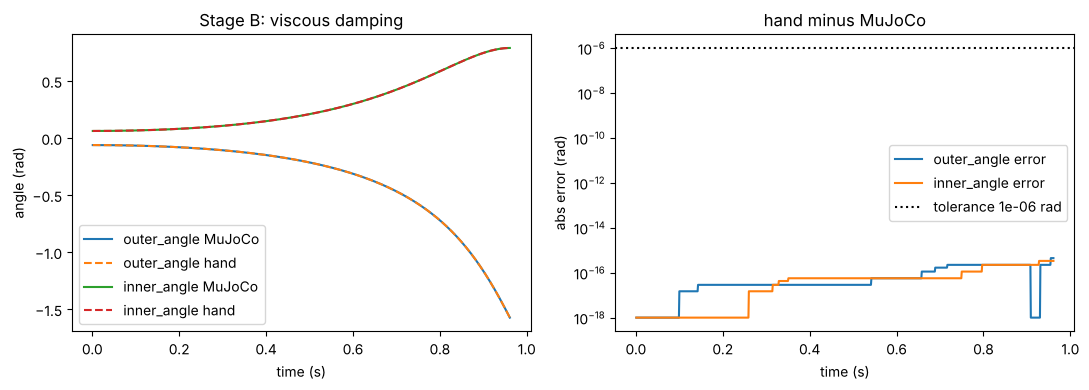

saved the data


In [8]:
# ─────────────────────────────────────────────
# STEP 8: run with viscous damping and compare with MuJoCo
# What we have: start_angles, damping 0.04 N*m*s/rad on both hinges, no Coulomb friction
# What we want: hand and MuJoCo trajectories, and the energy balance of equation 2.3
# Why: pass test of stage B: max abs angle error <= 1e-6 rad; energy lost = work done against damping
# ─────────────────────────────────────────────

TOLERANCE_RAD = 1e-6  # fixed before looking
MAX_STEPS = 30000

hand_result = simulate(start_angles, start_rates, MAX_STEPS, viscous_damping=VISCOUS_DAMPING_VALUE, stop_below_horizontal=True)
mujoco_result = run_mujoco(start_angles, MAX_STEPS, viscous_damping=VISCOUS_DAMPING_VALUE, stop_below_horizontal=True)
angle_error = compare_angles(hand_result, mujoco_result, TOLERANCE_RAD, "stage B")

# equation 2.3: E_k - E_0 = - integral of b (q1_dot^2 + q2_dot^2) dt  (trapezoid rule on the logged rates)
rates_with_start = np.vstack([start_rates, hand_result["rates"]])  # rows 0..N, row 0 is the start
damping_power = VISCOUS_DAMPING_VALUE * np.sum(rates_with_start**2, axis=1)  # W
dissipated_energy = np.cumsum(0.5 * (damping_power[1:] + damping_power[:-1]) * time_step)  # J, at each logged row
start_energy = total_energy(np.concatenate([start_angles, start_rates]))
energy_balance_residual = (hand_result["energy"] - start_energy) + dissipated_energy  # should be ~0
print(f"energy lost over the fall = {dissipated_energy[-1]:.6f} J, balance residual = {np.abs(energy_balance_residual).max():.2e} J")
assert np.abs(energy_balance_residual).max() < 1e-5, "energy balance (equation 2.3) not satisfied"
assert np.all(np.diff(hand_result["energy"]) <= 1e-12), "energy should only decrease with damping"

# equation 2.4: growth rate of a small tilt with damping
beta = VISCOUS_DAMPING_VALUE / pivot_inertia
gravity_rate = gravity_energy_scale / pivot_inertia
growth_rate = (-beta + np.sqrt(beta**2 + 4 * gravity_rate)) / 2
print(f"linear growth rate with damping = {growth_rate:.3f} 1/s (undamped {np.sqrt(gravity_rate):.3f} 1/s)")

plot_overlay(hand_result, mujoco_result, angle_error, TOLERANCE_RAD, "Stage B: viscous damping", "stage_b_overlay")
np.savez(os.path.join(RESULT_DIR, f"hand_stage_b_{TIMESTAMP}.npz"),
         angles=hand_result["angles"], rates=hand_result["rates"], energy=hand_result["energy"])
print("saved the data")
